# Task 1 — Final TEST evaluation: binary Alzheimer classification

This notebook is the **final evaluation stage** of the tabular workflow.

The model family and hyperparameters were selected in notebook 08 using only TRAIN + VALIDATION. The complete preparation + estimator pipeline was then refitted on those development observations and serialized.

The rules here are deliberately strict:

```text
load frozen model
        ↓
recover protected TEST observations
        ↓
predict
        ↓
compute final metrics and diagnostics
        ↓
describe the frozen model
```

There is **no model fitting, hyperparameter optimization, threshold optimization, feature reselection, or algorithm reselection** after TEST is opened. If TEST performance is weaker than expected, that is a scientific result rather than a reason to tune again.


## 1. What is being evaluated?

The serialized artifact from notebook 08 contains both the learned preparation and the optimized estimator. It is therefore the object that represents the final predictive system.

This notebook evaluates three aspects:

1. **predictive performance** on untouched TEST observations;
2. **error structure**, using task-appropriate visual diagnostics;
3. **model identity**, including the selected family, hyperparameters, feature set, and the development criterion that produced it.

The final TEST result estimates generalization under the fixed split defined earlier in the workflow. It does not establish performance under external distribution shift, new sites, new sequence families, or other stronger novelty scenarios unless the split itself represents those conditions.


In [1]:
from pathlib import Path
import json
import re
import sys

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display, Markdown
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    explained_variance_score,
    f1_score,
    log_loss,
    matthews_corrcoef,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    median_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize

sns.set_theme(style="whitegrid", context="notebook")
PASTEL_BLUE = sns.light_palette("steelblue", as_cmap=True)
PALETTE = "pastel"

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

Python: 3.14.8
pandas: 3.0.6
scikit-learn: 1.9.1
joblib: 1.6.0


## 2. Locate the frozen artifacts

Notebook 09 requires the outputs of notebooks 06 and 08. In particular, it needs the frozen split assignments and the final optimized model.


In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository root.")

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET = "synthetic_alzheimer"
DATASET_DIR = PROJECT_ROOT / "data" / DATASET
RAW_DATA_PATH = DATASET_DIR / "raw_data" / "synthetic_alzheimer_patients_1000.csv"
METADATA_PATH = DATASET_DIR / "raw_data" / "metadata.json"
PREPARATION_DIR = PROJECT_ROOT / "results" / DATASET / "ml_preparation"
HPO_DIR = PROJECT_ROOT / "results" / DATASET / "hyperparameter_optimization"
FINAL_EVAL_DIR = PROJECT_ROOT / "results" / DATASET / "final_test_evaluation"
TABLES_DIR = FINAL_EVAL_DIR / "tables"
FIGURES_DIR = FINAL_EVAL_DIR / "figures"

for directory in [TABLES_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PREPARATION_MANIFEST_PATH = PREPARATION_DIR / "preparation_manifest.json"
HPO_MANIFEST_PATH = HPO_DIR / "hpo_manifest.json"
BEST_HYPERPARAMETERS_PATH = HPO_DIR / "best_hyperparameters.json"
SELECTED_FEATURES_PATH = HPO_DIR / "final_selected_feature_names.json"
FAMILY_RESULTS_PATH = HPO_DIR / "tables" / "family_best_cv_results.csv"

required = [
    RAW_DATA_PATH,
    METADATA_PATH,
    PREPARATION_MANIFEST_PATH,
    HPO_MANIFEST_PATH,
    BEST_HYPERPARAMETERS_PATH,
    SELECTED_FEATURES_PATH,
    FAMILY_RESULTS_PATH,
]
missing = [path for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Required artifacts are missing. Run notebooks 06, 07, and 08 first:\n" +
        "\n".join(f" - {path}" for path in missing)
    )

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATASET)
print("Final TEST output:", FINAL_EVAL_DIR.relative_to(PROJECT_ROOT))

Project root: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
Dataset: synthetic_alzheimer
Final TEST output: results/synthetic_alzheimer/final_test_evaluation


## 3. Audit the development history before opening TEST

The HPO manifest must confirm that TEST was not used during screening or optimization. We load the development metadata first and stop if that contract has been violated.


In [3]:
with METADATA_PATH.open("r", encoding="utf-8") as file:
    metadata = json.load(file)
with PREPARATION_MANIFEST_PATH.open("r", encoding="utf-8") as file:
    preparation_manifest = json.load(file)
with HPO_MANIFEST_PATH.open("r", encoding="utf-8") as file:
    hpo_manifest = json.load(file)
with BEST_HYPERPARAMETERS_PATH.open("r", encoding="utf-8") as file:
    best_hyperparameters = json.load(file)
with SELECTED_FEATURES_PATH.open("r", encoding="utf-8") as file:
    final_selected_features = json.load(file)

if hpo_manifest.get("test_used", True):
    raise RuntimeError("HPO manifest indicates that TEST was already used. Stop and audit the workflow.")
if best_hyperparameters.get("test_used", True):
    raise RuntimeError("Best-hyperparameters record indicates TEST contamination.")

FINAL_MODEL_PATH = PROJECT_ROOT / hpo_manifest["final_model"]
SPLIT_ASSIGNMENTS_PATH = PROJECT_ROOT / preparation_manifest["artifacts"]["split_assignments"]
if not FINAL_MODEL_PATH.exists() or not SPLIT_ASSIGNMENTS_PATH.exists():
    raise FileNotFoundError("Final optimized model or split assignments are missing.")

family_results = pd.read_csv(FAMILY_RESULTS_PATH)
selected_family = hpo_manifest["selected_family"]
best_cv_value = float(hpo_manifest["best_cv_value"])
best_params = dict(hpo_manifest["selected_hyperparameters"])

print("Frozen family:", selected_family)
print("Primary HPO metric:", hpo_manifest["primary_metric"])
print("Best cross-validated development score:", best_cv_value)
print("Development data used during HPO:", hpo_manifest["development_data"])
print("Final model artifact:", FINAL_MODEL_PATH.relative_to(PROJECT_ROOT))
print("TEST used before this notebook: False")

Frozen family: SVM
Primary HPO metric: MCC
Best cross-validated development score: 0.4412536277557112
Development data used during HPO: TRAIN + VALIDATION
Final model artifact: results/synthetic_alzheimer/hyperparameter_optimization/artifacts/final_optimized_model.joblib
TEST used before this notebook: False


## 4. Reproduce deterministic raw-data preparation

Only deterministic operations are reproduced here: column-name normalization, schema checks, type conversion, and the fixed feature formulas defined earlier in the course.

Data-dependent transformations such as imputation, scaling, and supervised feature selection are **not recalculated here**. They already live inside the frozen serialized pipeline.


In [4]:
def normalize_column_name(name: str) -> str:
    name = str(name).strip().lower()
    name = re.sub(r"[^0-9a-zA-Z]+", "_", name)
    return re.sub(r"_+", "_", name).strip("_")


def normalized_roles(metadata: dict) -> dict:
    return {
        "id": normalize_column_name(metadata["col_id"]),
        "target": normalize_column_name(metadata["label"]),
        "numerical": [normalize_column_name(c) for c in metadata["numerical_column"]],
        "categorical": [normalize_column_name(c) for c in metadata["categorical_column"]],
    }


ROLES = normalized_roles(metadata)
ID_COLUMN = ROLES["id"]
TARGET_COLUMN = ROLES["target"]
ORIGINAL_NUMERICAL = ROLES["numerical"]
CATEGORICAL_COLUMNS = ROLES["categorical"]


def clean_raw_table(frame: pd.DataFrame, require_target: bool = True) -> pd.DataFrame:
    out = frame.copy()
    out.columns = [normalize_column_name(c) for c in out.columns]
    required_columns = [ID_COLUMN, *ORIGINAL_NUMERICAL, *CATEGORICAL_COLUMNS]
    if require_target:
        required_columns.append(TARGET_COLUMN)
    missing_columns = sorted(set(required_columns) - set(out.columns))
    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")
    out = out.drop_duplicates().copy()
    if out[ID_COLUMN].isna().any() or out[ID_COLUMN].duplicated().any():
        raise ValueError("Identifier must be present and unique.")
    for column in [*ORIGINAL_NUMERICAL, *CATEGORICAL_COLUMNS]:
        out[column] = pd.to_numeric(out[column], errors="raise")
    for column in CATEGORICAL_COLUMNS:
        observed = set(out[column].dropna().unique().tolist())
        if not observed.issubset({0, 1}):
            raise ValueError(f"{column} contains values outside {{0, 1}}: {observed}")
    if TARGET_COLUMN in out.columns:
        out[TARGET_COLUMN] = pd.to_numeric(out[TARGET_COLUMN], errors="raise").astype(int)
        if require_target and out[TARGET_COLUMN].isna().any():
            raise ValueError("TEST target cannot contain missing values.")
    return out

In [5]:
def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    height = out["height_cm"].replace(0, np.nan)
    out["pulse_pressure_mmhg"] = out["systolic_bp_mmhg"] - out["diastolic_bp_mmhg"]
    out["mean_arterial_pressure_mmhg"] = (
        out["systolic_bp_mmhg"] + 2.0 * out["diastolic_bp_mmhg"]
    ) / 3.0
    out["waist_height_ratio"] = out["waist_cm"] / height
    cardiometabolic = [
        "hypertension", "diabetes_type2", "dyslipidemia",
        "cardiovascular_disease", "stroke_history",
    ]
    neurobehavioral = [
        "depression_history", "traumatic_brain_injury",
        "sleep_disorder", "hearing_loss",
    ]
    out["cardiometabolic_risk_count"] = out[cardiometabolic].sum(axis=1, min_count=1)
    out["neurobehavioral_risk_count"] = out[neurobehavioral].sum(axis=1, min_count=1)
    return out.replace([np.inf, -np.inf], np.nan)

## 5. Open the protected TEST partition

TEST membership is recovered from the exact split-assignment artifact created in notebook 06. The test rows are then taken from the original raw dataset and passed through the same deterministic feature construction used during development.

This is the first stage in the workflow where TEST targets are used for model evaluation.


In [6]:
split_assignments = pd.read_csv(SPLIT_ASSIGNMENTS_PATH)
split_assignments.columns = [normalize_column_name(c) for c in split_assignments.columns]
split_assignments["split"] = split_assignments["split"].astype(str).str.upper()

test_assignments = split_assignments.loc[
    split_assignments["split"].eq("TEST"), [ID_COLUMN, TARGET_COLUMN, "split"]
].copy()
expected_test_n = int(preparation_manifest["split_sizes"]["test"])
if len(test_assignments) != expected_test_n:
    raise AssertionError(f"Expected {expected_test_n} TEST observations, found {len(test_assignments)}.")

raw_all = pd.read_csv(RAW_DATA_PATH)
raw_all.columns = [normalize_column_name(c) for c in raw_all.columns]
raw_all[ID_COLUMN] = raw_all[ID_COLUMN].astype(str)
test_assignments[ID_COLUMN] = test_assignments[ID_COLUMN].astype(str)

# Merge preserves the frozen TEST membership defined in notebook 06.
test_raw = test_assignments[[ID_COLUMN]].merge(raw_all, on=ID_COLUMN, how="left", validate="one_to_one")
if test_raw.isna().all(axis=1).any():
    raise ValueError("Some protected TEST identifiers could not be recovered from raw data.")

test_clean = clean_raw_table(test_raw, require_target=True)
test_engineered = engineer_features(test_clean)
ENGINEERED_NUMERICAL = ['pulse_pressure_mmhg', 'mean_arterial_pressure_mmhg', 'waist_height_ratio', 'cardiometabolic_risk_count', 'neurobehavioral_risk_count']
NUMERICAL_FEATURES = ORIGINAL_NUMERICAL + ENGINEERED_NUMERICAL
FEATURE_COLUMNS = NUMERICAL_FEATURES + CATEGORICAL_COLUMNS

X_test = test_engineered[FEATURE_COLUMNS].copy()
y_test = test_engineered[TARGET_COLUMN].astype(int).to_numpy()

assert len(X_test) == expected_test_n
assert TARGET_COLUMN not in X_test.columns
assert ID_COLUMN not in X_test.columns

print("Protected TEST observations:", len(X_test))
print("Candidate predictors supplied to the frozen pipeline:", X_test.shape[1])
print("TEST identifiers recovered exactly from the frozen split manifest: PASS")

Protected TEST observations: 150
Candidate predictors supplied to the frozen pipeline: 34
TEST identifiers recovered exactly from the frozen split manifest: PASS


## 6. Describe the already-selected model

The model is not selected in this notebook. It has already won the Optuna comparison among the three screened families using development cross-validation.

We record exactly what is being tested before examining the TEST metrics.


In [7]:
final_model = joblib.load(FINAL_MODEL_PATH)
if not hasattr(final_model, "predict"):
    raise TypeError("The serialized artifact does not expose predict().")

pipeline_steps = list(getattr(final_model, "named_steps", {}).keys())
model_step = final_model.named_steps.get("model") if hasattr(final_model, "named_steps") else final_model

model_specification = pd.DataFrame({
    "item": [
        "Selected family",
        "Estimator class",
        "Selection basis",
        "Development rows",
        "CV folds",
        "Best development CV value",
        "Candidate families optimized",
        "Candidate predictors before preparation",
        "Predictors retained by final selector",
        "Final refit data",
        "Pipeline steps",
    ],
    "value": [
        selected_family,
        model_step.__class__.__name__,
        hpo_manifest["primary_metric"],
        best_hyperparameters["development_rows"],
        best_hyperparameters["cv_folds"],
        best_cv_value,
        ", ".join(hpo_manifest["input_top3_families"]),
        len(preparation_manifest["candidate_features"]),
        len(final_selected_features),
        best_hyperparameters["final_refit"],
        " -> ".join(pipeline_steps),
    ],
})

display(model_specification)
print("Frozen hyperparameters:")
print(json.dumps(best_params, indent=2))
print("\nSelected predictor names:")
print(final_selected_features)

,item,value
0,Selected family,SVM
1,Estimator class,SVC
2,Selection basis,MCC
3,Development rows,850
4,CV folds,5
5,Best development CV value,0.441254
6,Candidate families optimized,"SVM, Logistic Regression, HistGradientBoosting"
7,Candidate predictors before preparation,34
8,Predictors retained by final selector,21
9,Final refit data,complete TRAIN + VALIDATION development set


Frozen hyperparameters:
{
  "kernel": "linear",
  "C": 0.04235455276099052,
  "class_weight": null
}

Selected predictor names:
['age', 'bmi', 'waist_hip_ratio', 'systolic_bp_mmhg', 'diastolic_bp_mmhg', 'pulse_pressure_mmhg', 'mean_arterial_pressure_mmhg', 'cardiometabolic_risk_count', 'neurobehavioral_risk_count', 'physical_inactivity', 'hypertension', 'diabetes_type2', 'dyslipidemia', 'cardiovascular_disease', 'stroke_history', 'depression_history', 'family_history_alzheimer', 'chronic_kidney_disease', 'hearing_loss', 'allergy_medication', 'allergy_food']


## 7. Final TEST predictions and metrics

The next cell performs the frozen model's TEST prediction and computes task-appropriate metrics. These values are the final held-out evaluation for this workflow.


In [8]:
# The frozen model is evaluated on TEST exactly as stored. There is no model fitting in this notebook.
y_pred = final_model.predict(X_test)
classes = np.asarray(final_model.classes_)
if set(classes.tolist()) != {0, 1}:
    raise ValueError(f"Expected binary classes {{0, 1}}, found {classes.tolist()}")

if not hasattr(final_model, "predict_proba"):
    raise TypeError("Final classifier does not provide predict_proba().")
probabilities = final_model.predict_proba(X_test)
positive_index = int(np.where(classes == 1)[0][0])
y_score = probabilities[:, positive_index]

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp) if (tn + fp) else np.nan

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall_sensitivity": recall_score(y_test, y_pred, zero_division=0),
    "specificity": specificity,
    "f1": f1_score(y_test, y_pred, zero_division=0),
    "mcc": matthews_corrcoef(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_score),
    "average_precision": average_precision_score(y_test, y_score),
    "log_loss": log_loss(y_test, probabilities, labels=classes),
    "brier_score": brier_score_loss(y_test, y_score),
}
metrics_table = pd.DataFrame({"metric": metrics.keys(), "test_value": metrics.values()})
metrics_table.to_csv(TABLES_DIR / "final_test_metrics.csv", index=False)
display(metrics_table)

report = pd.DataFrame(classification_report(
    y_test, y_pred, labels=[0, 1], target_names=["No Alzheimer", "Alzheimer"],
    output_dict=True, zero_division=0,
)).T
report.to_csv(TABLES_DIR / "classification_report.csv")
display(report)

predictions = pd.DataFrame({
    ID_COLUMN: test_clean[ID_COLUMN].astype(str).to_numpy(),
    "y_true": y_test,
    "y_pred": y_pred,
    "probability_alzheimer": y_score,
    "correct": y_test == y_pred,
})
predictions.to_csv(TABLES_DIR / "test_predictions.csv", index=False)

,metric,test_value
0,accuracy,0.760000
1,balanced_accuracy,0.699346
2,precision,0.702703
3,recall_sensitivity,0.509804
4,specificity,0.888889
5,f1,0.590909
6,mcc,0.438128
7,roc_auc,0.806892
8,average_precision,0.724331
9,log_loss,0.495370


,precision,recall,f1-score,support
No Alzheimer,0.778761,0.888889,0.830189,99.00
Alzheimer,0.702703,0.509804,0.590909,51.00
accuracy,0.760000,0.760000,0.760000,0.76
macro avg,0.740732,0.699346,0.710549,150.00
weighted avg,0.752901,0.760000,0.748834,150.00


## 8. Final binary-classification diagnostics

A single scalar is not enough. We inspect the confusion matrix, score distributions, ranking behavior, precision-recall trade-off, and an exploratory calibration curve.

The decision threshold remains the estimator's frozen default. No threshold is optimized on TEST.


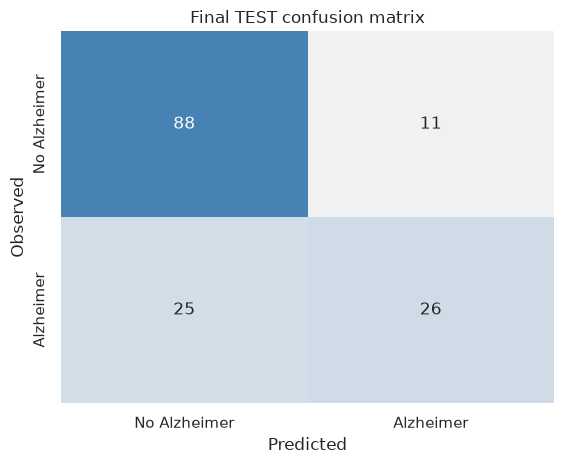

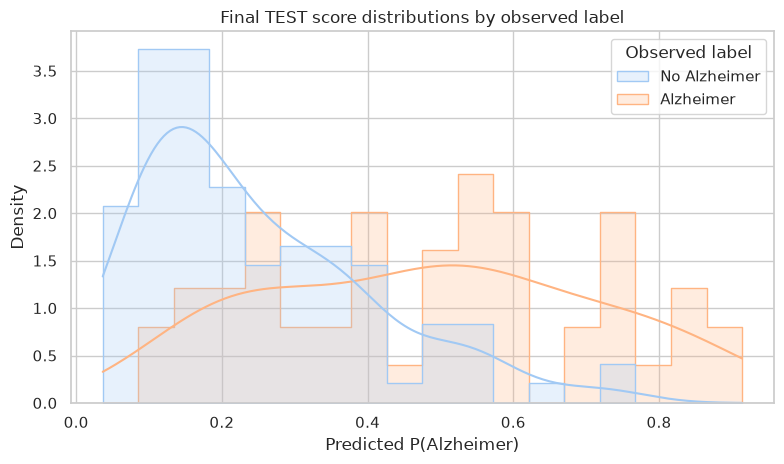

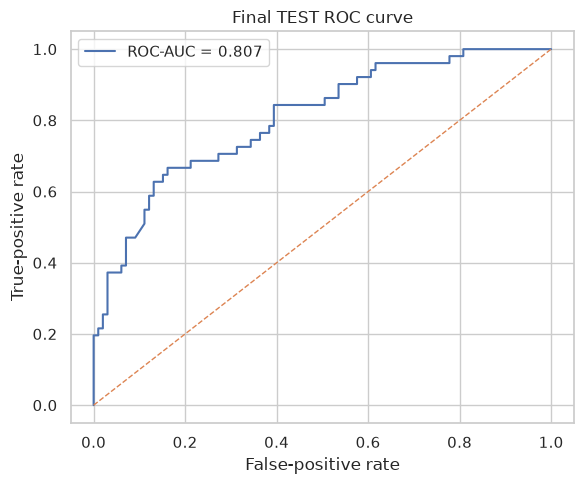

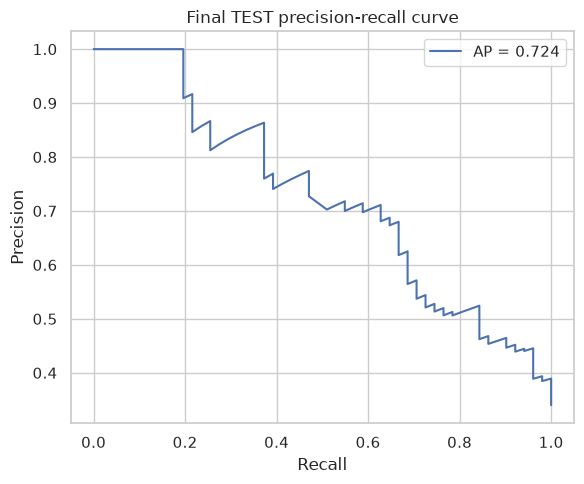

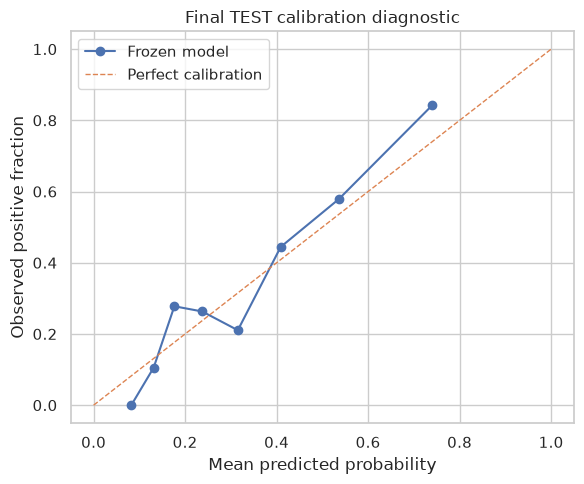

In [9]:
# Confusion matrix
plt.figure(figsize=(5.8, 4.8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap=PASTEL_BLUE, cbar=False,
    xticklabels=["No Alzheimer", "Alzheimer"],
    yticklabels=["No Alzheimer", "Alzheimer"],
)
plt.xlabel("Predicted")
plt.ylabel("Observed")
plt.title("Final TEST confusion matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_test_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

# Probability distributions by observed label
plot_scores = predictions.copy()
plot_scores["Observed label"] = plot_scores["y_true"].map({0: "No Alzheimer", 1: "Alzheimer"})
plt.figure(figsize=(8, 4.8))
sns.histplot(
    data=plot_scores, x="probability_alzheimer", hue="Observed label",
    bins=18, kde=True, stat="density", common_norm=False,
    element="step", palette="pastel",
)
plt.xlabel("Predicted P(Alzheimer)")
plt.title("Final TEST score distributions by observed label")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_test_probability_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

# ROC
fpr, tpr, _ = roc_curve(y_test, y_score)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {metrics['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Final TEST ROC curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_test_roc_curve.png", dpi=180, bbox_inches="tight")
plt.show()

# Precision-recall
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6, 5))
plt.plot(recall_curve, precision_curve, label=f"AP = {metrics['average_precision']:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final TEST precision-recall curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_test_precision_recall_curve.png", dpi=180, bbox_inches="tight")
plt.show()

# Calibration
fraction_pos, mean_pred = calibration_curve(y_test, y_score, n_bins=8, strategy="quantile")
plt.figure(figsize=(6, 5))
plt.plot(mean_pred, fraction_pos, marker="o", label="Frozen model")
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("Final TEST calibration diagnostic")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_test_calibration.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Interpretation of the final binary model

The interpretation below combines the frozen model identity with its final held-out behavior. A discrepancy between development CV and TEST is reported, not corrected by reopening model development.


In [10]:
cv_value = best_cv_value
test_primary = metrics["mcc"]
delta = test_primary - cv_value
summary_text = f"""
### Frozen model interpretation

The final model is **{selected_family}**, selected before TEST using Optuna cross-validation on the combined TRAIN + VALIDATION development set. The model was then refitted on the complete development set and serialized.

On the protected TEST partition it achieved **MCC = {metrics['mcc']:.3f}**, balanced accuracy = **{metrics['balanced_accuracy']:.3f}**, ROC-AUC = **{metrics['roc_auc']:.3f}**, and average precision = **{metrics['average_precision']:.3f}**. Sensitivity was **{metrics['recall_sensitivity']:.3f}** and specificity was **{metrics['specificity']:.3f}**, so the confusion matrix should be examined together with the aggregate scores.

The development CV estimate for the primary metric was **{cv_value:.3f}**. The TEST-minus-CV difference is **{delta:+.3f}**. This difference is reported as final generalization evidence; it is **not** used to reopen hyperparameter optimization or model selection.

The serialized object contains the learned preparation, feature selection, and optimized estimator, which means future target-free observations can be transformed and predicted with the same frozen workflow.
"""
display(Markdown(summary_text))


### Frozen model interpretation

The final model is **SVM**, selected before TEST using Optuna cross-validation on the combined TRAIN + VALIDATION development set. The model was then refitted on the complete development set and serialized.

On the protected TEST partition it achieved **MCC = 0.438**, balanced accuracy = **0.699**, ROC-AUC = **0.807**, and average precision = **0.724**. Sensitivity was **0.510** and specificity was **0.889**, so the confusion matrix should be examined together with the aggregate scores.

The development CV estimate for the primary metric was **0.441**. The TEST-minus-CV difference is **-0.003**. This difference is reported as final generalization evidence; it is **not** used to reopen hyperparameter optimization or model selection.

The serialized object contains the learned preparation, feature selection, and optimized estimator, which means future target-free observations can be transformed and predicted with the same frozen workflow.


## 10. Freeze the final evaluation record

The final metrics, predictions, and model description are exported for later reporting. The serialized predictive model itself is not modified.

The resulting files document the complete hand-off from development to final evaluation and make it explicit that TEST did not trigger a new optimization cycle.


In [11]:
primary_test_value = metrics["mcc"]
cv_to_test_difference = primary_test_value - best_cv_value

summary_payload = {
    "dataset": DATASET,
    "task_type": "binary_classification",
    "evaluation_status": "final_test_evaluation",
    "selected_family": selected_family,
    "estimator_class": model_step.__class__.__name__,
    "selected_hyperparameters": best_params,
    "candidate_families_from_hpo": hpo_manifest["input_top3_families"],
    "primary_metric": hpo_manifest["primary_metric"],
    "development_cv_value": best_cv_value,
    "final_test_primary_value": float(primary_test_value),
    "test_minus_cv": float(cv_to_test_difference),
    "test_rows": int(len(X_test)),
    "candidate_predictors": int(len(FEATURE_COLUMNS)),
    "selected_predictors": final_selected_features,
    "all_test_metrics": {key: float(value) for key, value in metrics.items()},
    "final_model_artifact": str(FINAL_MODEL_PATH.relative_to(PROJECT_ROOT)),
    "model_refit_in_test_notebook": False,
    "test_used_for_hyperparameter_selection": False,
    "test_used_for_family_selection": False,
    "post_test_retuning_allowed": False,
}
with (FINAL_EVAL_DIR / "final_test_report.json").open("w", encoding="utf-8") as file:
    json.dump(summary_payload, file, indent=2)

hyperparameter_lines = "\n".join(
    f"- `{key}`: `{value}`" for key, value in best_params.items()
) or "- No non-default hyperparameters were required."
feature_lines = "\n".join(f"- `{feature}`" for feature in final_selected_features)
model_summary_md = f"""# Final selected model — {DATASET}

## Frozen selection

- **Task:** binary_classification
- **Selected family:** {selected_family}
- **Estimator:** {model_step.__class__.__name__}
- **Primary selection metric:** {hpo_manifest['primary_metric']}
- **Development CV value:** {best_cv_value:.6f}
- **Final TEST primary value:** {primary_test_value:.6f}
- **TEST minus development CV:** {cv_to_test_difference:+.6f}
- **Development data:** TRAIN + VALIDATION
- **Final evaluation data:** protected TEST only
- **Refit performed in TEST notebook:** no

## Hyperparameters

{hyperparameter_lines}

## Selected predictors

{feature_lines}

## Interpretation rule

The model, hyperparameters, preprocessing, and feature selector were frozen before TEST evaluation. TEST results quantify held-out generalization and must not be used to reopen model selection or hyperparameter optimization.
"""
(FINAL_EVAL_DIR / "final_model_summary.md").write_text(model_summary_md, encoding="utf-8")

checks = {
    "hpo_test_used_before_final_evaluation": bool(hpo_manifest.get("test_used", True)),
    "final_model_loaded": FINAL_MODEL_PATH.exists(),
    "protected_test_size_matches_manifest": len(X_test) == int(preparation_manifest["split_sizes"]["test"]),
    "target_not_in_model_input": TARGET_COLUMN not in X_test.columns,
    "identifier_not_in_model_input": ID_COLUMN not in X_test.columns,
    "test_predictions_complete": len(y_pred) == len(X_test),
    "model_refit_in_test_notebook": False,
}
validation_table = pd.DataFrame({"check": checks.keys(), "value": checks.values()})
display(validation_table)
if checks["hpo_test_used_before_final_evaluation"]:
    raise AssertionError("TEST was used before final evaluation.")
if not all(value for key, value in checks.items() if key not in ["hpo_test_used_before_final_evaluation", "model_refit_in_test_notebook"]):
    raise AssertionError("Final TEST validation failed.")
if checks["model_refit_in_test_notebook"]:
    raise AssertionError("The final TEST notebook must not refit the model.")
print("FINAL TEST EVALUATION: PASS")
print("No tuning, refitting, or model reselection was performed after opening TEST.")

,check,value
0,hpo_test_used_before_final_evaluation,False
1,final_model_loaded,True
2,protected_test_size_matches_manifest,True
3,target_not_in_model_input,True
4,identifier_not_in_model_input,True
5,test_predictions_complete,True
6,model_refit_in_test_notebook,False


FINAL TEST EVALUATION: PASS
No tuning, refitting, or model reselection was performed after opening TEST.


## 11. Final workflow boundary

The classical supervised-learning workflow is now complete:

```text
raw data
   ↓
preprocessing / EDA / feature engineering
   ↓
scaling and partition design
   ↓
end-to-end preparation
   ↓
model-family screening on TRAIN + VALIDATION
   ↓
Optuna HPO with CV on TRAIN + VALIDATION
   ↓
refit frozen model on TRAIN + VALIDATION
   ↓
FINAL TEST EVALUATION  ← this notebook
```

After this point, the TEST result belongs in the report. If a new modeling decision is made because of TEST, a new independent evaluation dataset would be required to obtain a clean final estimate again.

The next scientifically stronger step is not to retune this same test set, but to evaluate the frozen artifact on genuinely new external data or under a more demanding split strategy when the application requires it.
